# 1. One basket

In [158]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path
sys.path.insert(0, str(Path("..").resolve()))

import numpy as np
import pandas as pd
import matplotlib

import matplotlib.pyplot as plt

from config import (
    OHLCV_DIR, ASSET_DAILY_PATH, ASSETS_PATH,
    DATE_COL, TIMESTAMP_COL, CLOSE_COL, ASSET_ID_COL, MARKET_SYMBOL_COL,
    VOLUME_COL, MIN_VOLUME_24H_USD,
)
from helperfunctions import HelperFunctions
helper = HelperFunctions()

print("Imports OK")

Imports OK


In [159]:
# --- Daten laden & vorverarbeiten ---
from helperfunctions import STABLECOIN_SYMBOLS

# Assets-Tabelle: asset_id <-> symbol
assets_df  = pd.read_parquet(ASSETS_PATH)[["asset_id", "symbol"]].drop_duplicates()
id_to_symbol = dict(zip(assets_df["asset_id"], assets_df["symbol"]))
sym_to_id    = dict(zip(assets_df["symbol"], assets_df["asset_id"]))

# Stablecoin asset_ids berechnen, werden aus der Point Cloud ausgeschlossen
excluded_ids: set[int] = set(
    assets_df.loc[assets_df["symbol"].isin(STABLECOIN_SYMBOLS), "asset_id"].tolist()
)
excluded_syms = sorted(assets_df.loc[assets_df["asset_id"].isin(excluded_ids), "symbol"])
print(f"Ausgeschlossene Stablecoins: {excluded_syms}")

ohlcv_files = sorted(OHLCV_DIR.glob("*.parquet"))
print(f"\nOHLCV-Dateien gefunden: {len(ohlcv_files)}")

raw = pd.concat([pd.read_parquet(f) for f in ohlcv_files], ignore_index=True)
raw["base_symbol"] = raw[MARKET_SYMBOL_COL].str.replace("USDT$", "", regex=True)
raw = raw.merge(assets_df.rename(columns={"symbol": "base_symbol"}), on="base_symbol", how="left")
raw = raw.dropna(subset=["asset_id"])
raw["asset_id"] = raw["asset_id"].astype(int)
raw[TIMESTAMP_COL] = pd.to_datetime(raw[TIMESTAMP_COL], utc=True)
raw[DATE_COL]      = raw[TIMESTAMP_COL].dt.normalize()

ohlcv_df = raw[[TIMESTAMP_COL, DATE_COL, ASSET_ID_COL, CLOSE_COL]].copy()

print(f"OHLCV geladen: {ohlcv_df.shape[0]:,} Zeilen | Assets: {ohlcv_df[ASSET_ID_COL].nunique()}")
print(f"Zeitraum: {ohlcv_df[DATE_COL].min().date()} → {ohlcv_df[DATE_COL].max().date()}")

universe_df = pd.read_parquet(ASSET_DAILY_PATH)
universe_df[DATE_COL] = pd.to_datetime(universe_df[DATE_COL], utc=True)
print(f"\nUniverse geladen: {universe_df.shape[0]:,} Zeilen")

Ausgeschlossene Stablecoins: ['PAXG', 'XAUT']

OHLCV-Dateien gefunden: 25
OHLCV geladen: 8,798,178 Zeilen | Assets: 47
Zeitraum: 2024-07-23 → 2026-07-22

Universe geladen: 29,523 Zeilen


In [160]:
# --- Basket-Konfiguration fuer die Point Cloud ---
# Unabhaengig von 01_baskets.ipynb einstellbar: Anzahl Baskets und Grenzen
# ergeben sich aus POINTCLOUD_BASKET_UPPER_BOUNDS (aufsteigende Liste von N-1
# Volumen-Obergrenzen fuer einen N-Basket-Split -- siehe
# helperfunctions.HelperFunctions.assign_volume_basket). Fuer 2 Baskets reicht
# eine einzelne Grenze; 250M trennt hier "liquide Mehrheit" (Basket 1) von
# "kleinere/nischige Assets" (Basket 2), angelehnt an 01_baskets.ipynb's
# BASKET_3_UPPER (Grenze zwischen dortigem Basket 1+2 vs. 3+4).
POINTCLOUD_LOOKBACK_DAYS = 7
POINTCLOUD_BASKET_UPPER_BOUNDS = [250_000_000]

rolling_volume_df = helper.compute_rolling_volume_table(
    universe_df,
    id_column=ASSET_ID_COL,
    date_column=DATE_COL,
    volume_column=VOLUME_COL,
    lookback_days=POINTCLOUD_LOOKBACK_DAYS,
)

basket_labels = [f"Basket {n}" for n in range(1, len(POINTCLOUD_BASKET_UPPER_BOUNDS) + 2)]

print("Basket-Definitionen fuer die Point Cloud:")
for line in helper.describe_volume_baskets(POINTCLOUD_BASKET_UPPER_BOUNDS, MIN_VOLUME_24H_USD):
    print(f"  {line}")

Basket-Definitionen fuer die Point Cloud:
  Basket 2: $50,000,000 <= volume < $250,000,000
  Basket 1: volume >= $250,000,000


In [161]:
# --- Point Cloud erstellen: Lookback + Datum waehlen ---
import ipywidgets as widgets

data_min = ohlcv_df[DATE_COL].min().date()
data_max = ohlcv_df[DATE_COL].max().date()
max_lookback_days = (data_max - data_min).days + 1
# Slider auf 1-100 Tage begrenzt (PDF empfiehlt 20-60 Tage, "30 Tage ist ueblich");
# min() schuetzt nur fuer den Fall, dass der Datensatz selbst mal kuerzer als
# 100 Tage waere.
slider_max_lookback_days = min(100, max_lookback_days)
print(f"Verfuegbare Daten: {data_min} bis {data_max} (max. Lookback: {max_lookback_days} Tage)")

# Werden am Anfang auf None gesetzt und bei jeder ungueltigen Auswahl wieder
# zurueckgesetzt, damit nachfolgende Zellen bei einer fehlgeschlagenen Auswahl
# laut mit einem Fehler abbrechen, statt still das vorherige gueltige Fenster
# weiterzuverwenden.
result = pc = aids = syms = WINDOW_DAYS = DATE = None

def render(lookback_days, date):
    global result, pc, aids, syms, WINDOW_DAYS, DATE

    if date is None:
        result = pc = aids = syms = WINDOW_DAYS = DATE = None
        print("Bitte ein Datum waehlen.")
        return

    # DatePicker.min/max sind nur ein UI-Hinweis (natives <input type="date">) und
    # verhindern nicht zuverlaessig manuelle Eingaben ausserhalb des Bereichs ->
    # hier hart gegen die tatsaechlich verfuegbaren Daten pruefen.
    if date < data_min or date > data_max:
        result = pc = aids = syms = WINDOW_DAYS = DATE = None
        print(f"Bitte ein Datum zwischen {data_min} und {data_max} waehlen.")
        return

    start_date = date - pd.Timedelta(days=lookback_days - 1)
    if start_date < data_min:
        result = pc = aids = syms = WINDOW_DAYS = DATE = None
        print(
            f"Lookback von {lookback_days} Tagen reicht vor {data_min} zurueck "
            "— kuerzeren Lookback oder spaeteres Datum waehlen."
        )
        return

    date_ts = pd.Timestamp(date, tz="UTC")

    result_local = helper.build_point_cloud(
        ohlcv_df         = ohlcv_df,
        universe_df      = universe_df,
        end_date         = date_ts,
        window_size_days = lookback_days,
        exclude_asset_ids= excluded_ids,
    )

    if result_local is None:
        result = pc = aids = syms = WINDOW_DAYS = DATE = None
        print("Keine Daten fuer dieses Fenster — anderen Lookback/Datum waehlen.")
        return

    # In Notebook-Globals schreiben, damit nachfolgende Zellen pc/syms/result
    # wie bisher unveraendert weiterverwenden koennen.
    result = result_local
    pc     = result["point_cloud"]
    aids   = result["asset_ids"]
    syms   = [id_to_symbol.get(i, f"ID:{i}") for i in aids]
    WINDOW_DAYS, DATE = lookback_days, date_ts

    print("=" * 55)
    print(f"Fenster:      {result['start_date'].date()} → {result['end_date'].date()}  ({lookback_days} Tage)")
    print(f"Punkte (w):   {result['n_points']}   ← Anzahl 5min-Kerzen")
    print(f"Dimensionen:  {result['n_dimensions']}  ← Anzahl Assets (ohne Stablecoins)")
    print(f"Point-Cloud-Shape: {pc.shape}")
    print(f"Assets: {syms}")
    print("=" * 55)
    df_preview = pd.DataFrame(pc[:5], columns=syms, index=result["timestamps"][:5])
    df_preview.index.name = "timestamp"
    display(df_preview.style.format("{:+.4%}"))

lookback_slider = widgets.IntSlider(
    value=min(30, slider_max_lookback_days), min=1, max=slider_max_lookback_days, step=1,
    description="Lookback (Tage):", continuous_update=False,
    style={"description_width": "initial"},
)
date_picker = widgets.DatePicker(description="Datum:", value=data_max, min=data_min, max=data_max)

lookback_minus_button = widgets.Button(description="-1 Tag", layout=widgets.Layout(width="80px"))
lookback_plus_button = widgets.Button(description="+1 Tag", layout=widgets.Layout(width="80px"))

def on_lookback_minus_clicked(button):
    if lookback_slider.value > lookback_slider.min:
        lookback_slider.value -= 1

def on_lookback_plus_clicked(button):
    if lookback_slider.value < lookback_slider.max:
        lookback_slider.value += 1

lookback_minus_button.on_click(on_lookback_minus_clicked)
lookback_plus_button.on_click(on_lookback_plus_clicked)

controls = widgets.interactive(render, lookback_days=lookback_slider, date=date_picker)
display(widgets.VBox([
    widgets.HBox([lookback_slider, lookback_minus_button, lookback_plus_button]),
    date_picker,
    controls.children[-1],
]))

Verfuegbare Daten: 2024-07-23 bis 2026-07-22 (max. Lookback: 730 Tage)


In [162]:
# --- Korrelationsdistanzmatrix aus der Point Cloud ---
# pc ist die Return-Matrix (n_timestamps x n_assets); helper.correlation_distance
# erwartet ein DataFrame mit Assets als Spalten (genau wie "returns" in build_window_input).
returns_df = pd.DataFrame(pc, columns=syms, index=result["timestamps"])
dist_matrix = helper.correlation_distance(returns_df)

print(f"Distanzmatrix-Shape: {dist_matrix.shape}")
print(f"epsilon-Bereich: [0, {dist_matrix.max():.4f}]  (sqrt(2) = {np.sqrt(2):.4f} = keine Korrelation)")


Distanzmatrix-Shape: (29, 29)
epsilon-Bereich: [0, 1.2857]  (sqrt(2) = 1.4142 = keine Korrelation)


In [163]:
corr = np.corrcoef(returns_df.to_numpy().T)

pd.DataFrame(corr)

,0,1,2,3,4,5,6,7,8,9,...,19,20,21,22,23,24,25,26,27,28
0,1.000000,0.313440,0.536507,0.520394,0.521416,0.426104,0.496726,0.468511,0.567598,0.552331,...,0.483850,0.351676,0.525817,0.539521,0.390408,0.532454,0.207542,0.522589,0.417119,0.432577
1,0.313440,1.000000,0.435440,0.486793,0.458081,0.367857,0.434251,0.392491,0.469275,0.476455,...,0.413482,0.292715,0.432603,0.458327,0.322479,0.453255,0.176796,0.360295,0.329398,0.361030
2,0.536507,0.435440,1.000000,0.723265,0.718243,0.570211,0.673121,0.662510,0.779591,0.768135,...,0.681045,0.470751,0.723638,0.749606,0.543675,0.731621,0.255933,0.595216,0.553174,0.569596
3,0.520394,0.486793,0.723265,1.000000,0.813543,0.598475,0.704391,0.653367,0.807432,0.808420,...,0.673126,0.478307,0.760429,0.796390,0.542939,0.756168,0.281092,0.614902,0.552127,0.602033
4,0.521416,0.458081,0.718243,0.813543,1.000000,0.599844,0.709659,0.658450,0.837509,0.809080,...,0.654638,0.497153,0.801609,0.814925,0.553543,0.761875,0.308737,0.620027,0.537947,0.603521
5,0.426104,0.367857,0.570211,0.598475,0.599844,1.000000,0.553511,0.538196,0.626439,0.627354,...,0.532448,0.391968,0.591321,0.601970,0.440528,0.593374,0.223814,0.482521,0.442398,0.465214
6,0.496726,0.434251,0.673121,0.704391,0.709659,0.553511,1.000000,0.619244,0.749232,0.728731,...,0.637478,0.477068,0.700180,0.709276,0.535760,0.712035,0.261142,0.585832,0.579950,0.582966
7,0.468511,0.392491,0.662510,0.653367,0.658450,0.538196,0.619244,1.000000,0.717836,0.720223,...,0.619461,0.444086,0.702770,0.670526,0.515657,0.690561,0.249908,0.545019,0.506453,0.516887
8,0.567598,0.469275,0.779591,0.807432,0.837509,0.626439,0.749232,0.717836,1.000000,0.852767,...,0.715846,0.529099,0.825412,0.830299,0.599627,0.814362,0.307207,0.669995,0.591869,0.623791
9,0.552331,0.476455,0.768135,0.808420,0.809080,0.627354,0.728731,0.720223,0.852767,1.000000,...,0.715129,0.513555,0.809212,0.820986,0.588677,0.804634,0.292615,0.643812,0.592216,0.608502


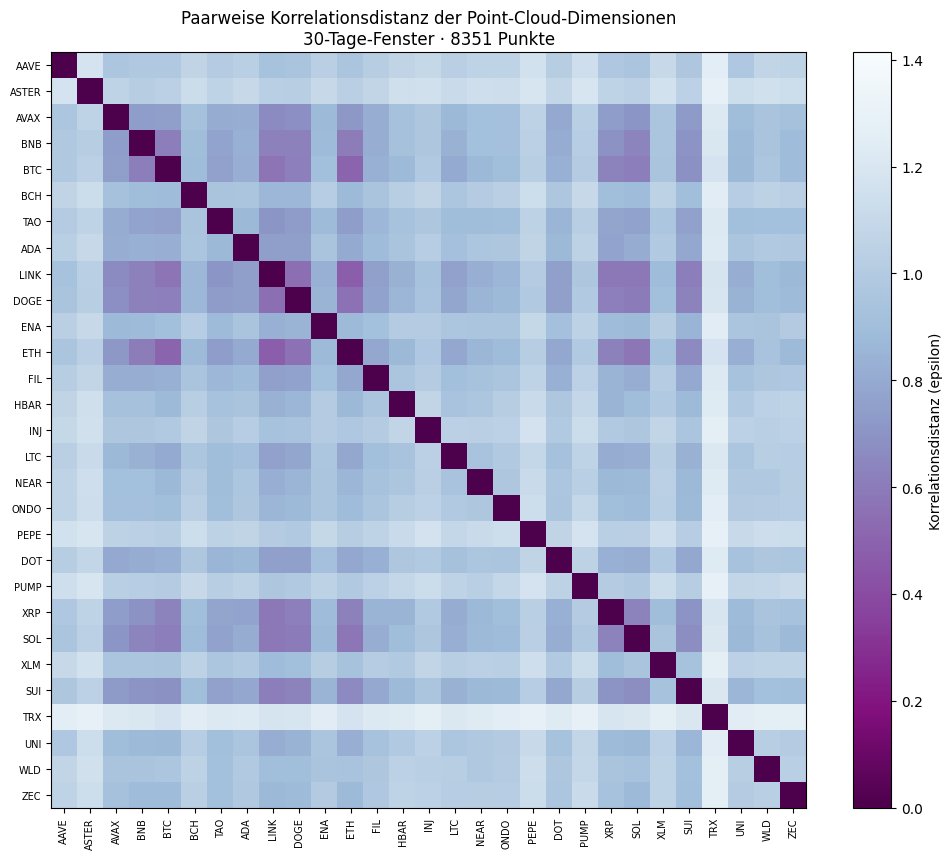

Top-10 Paare mit kleinster Distanz (staerkste Ko-Bewegung):
LINK  ETH     0.478857
BTC   ETH     0.502973
LINK  DOGE    0.542648
DOGE  ETH     0.563328
BTC   LINK    0.570071
ETH   SOL     0.577573
LINK  SOL     0.582582
      XRP     0.590912
DOGE  SOL     0.598354
BNB   ETH     0.603094
dtype: float64

Top-5 Paare mit groesster Distanz (am wenigsten verwandt):
XLM    TRX    1.269903
INJ    TRX    1.271679
PEPE   TRX    1.281684
ASTER  TRX    1.283125
PUMP   TRX    1.285681


In [164]:
# --- Visualisierung 4: Distanz-Heatmap aller Assets ---
dist_df = pd.DataFrame(dist_matrix, columns=syms, index=syms)

fig, ax = plt.subplots(figsize=(max(8, len(syms) * 0.35), max(6, len(syms) * 0.3)))
colormax = np.sqrt(2)  # theoretischer Maximalwert (keine Korrelation) -> Farbskala tagesunabhaengig fix
im = ax.imshow(dist_df.values, vmin=0, vmax=colormax, cmap="BuPu_r", aspect="auto")
plt.colorbar(im, ax=ax, label="Korrelationsdistanz (epsilon)")
ax.set_xticks(range(len(syms))); ax.set_xticklabels(syms, rotation=90, fontsize=7)
ax.set_yticks(range(len(syms))); ax.set_yticklabels(syms, fontsize=7)
ax.set_title(f"Paarweise Korrelationsdistanz der Point-Cloud-Dimensionen\n{WINDOW_DAYS}-Tage-Fenster · {result['n_points']} Punkte")
plt.tight_layout()
plt.show()
plt.close("all")

# Kleine Distanz = aehnliches Verhalten -> aufsteigend sortieren fuer die "engsten" Paare.
# .dropna() nach .stack() ist noetig, weil pandas >= 2.1 (stack(future_stack)) bzw.
# 3.0 (jetzt Default) die durch .where() maskierten (untere Dreiecks-)Werte NICHT
# mehr automatisch verwirft -> ohne dropna() landen die als NaN maskierten Zellen
# als "groesste Distanz" ganz am Ende der Sortierung (NaN sortiert immer zuletzt).
pairs = (
    dist_df.where(np.triu(np.ones(dist_df.shape), k=1).astype(bool))
    .stack()
    .dropna()
    .sort_values(ascending=True)
)
print("Top-10 Paare mit kleinster Distanz (staerkste Ko-Bewegung):")
print(pairs.head(10))
print("\nTop-5 Paare mit groesster Distanz (am wenigsten verwandt):")
print(pairs.tail(5).to_string())

Merge Scale (fest): 1.0


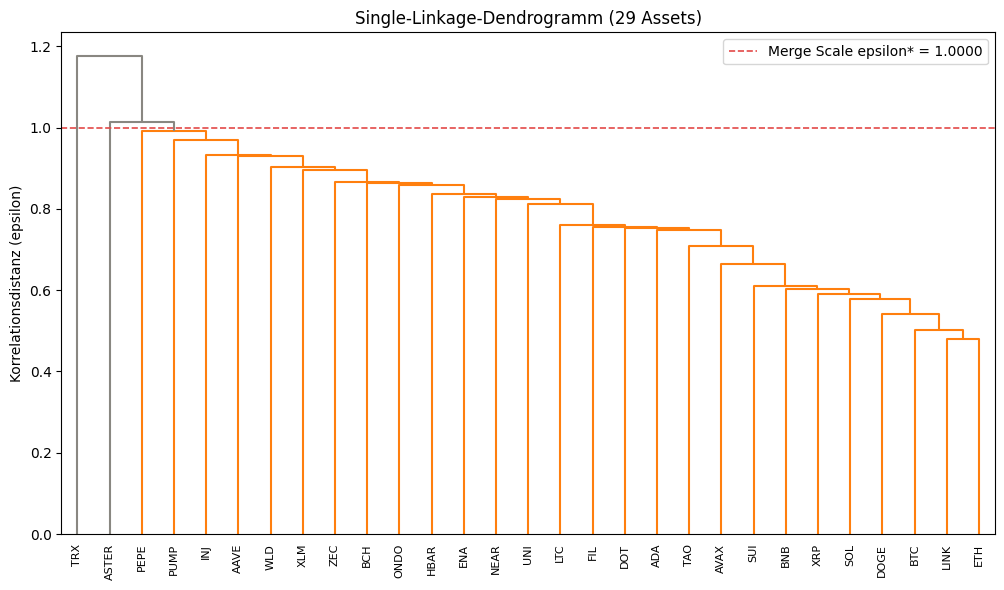

In [165]:
# --- Visualisierung 5: Dendrogramm der Assets ---
# Zeigt den Cluster-Baum: Assets, die frueh (niedrige Distanz) zusammengefuehrt
# werden, haben ein sehr aehnliches Return-Verhalten. Je hoeher der Merge-Punkt
# auf der y-Achse, desto schwaecher die Verbindung.
from cloudvisualisation import plot_dendrogram

# Merge Scale fest auf 1.0 -- markiert als rote Linie einen festen Referenzwert
# statt eines pro Fenster neu abgeleiteten Werts.
merge_scale = 1.0
print(f"Merge Scale (fest): {merge_scale}")

z_dendro = plot_dendrogram(dist_matrix, syms, color_threshold=merge_scale)

In [166]:
# --- Visualisierung 7: Epsilon-Slider (Vietoris-Rips 1-Skelett) ---
# Assets als Knoten (MDS-Layout aus der Distanzmatrix). Kanten erscheinen, sobald
# die paarweise Korrelationsdistanz <= epsilon ist. Beim Hochziehen des Sliders sieht
# man live, wie isolierte Assets (epsilon=0) zu Cliquen verschmelzen.
from cloudvisualisation import plot_vietoris_rips_epsilon_slider

# max_edge_length fix auf sqrt(2) (theoretisches Maximum, keine Korrelation) statt
# des Default-Werts max(distance_matrix): sonst haette der Slider bei jeder
# Datumsauswahl eine andere Obergrenze (abhaengig von Fenster & Anzahl Assets).
plot_vietoris_rips_epsilon_slider(dist_matrix, syms, max_edge_length=np.sqrt(2))

In [167]:
# --- Visualisierung 8: Cluster-Lebensdauer-Barcode (H0-inspiriert) ---
# Hinweis: dies ist NICHT das strikte Vietoris-Rips-H0-Persistenzdiagramm (das
# haette genau n Balken, alle mit birth=0 — siehe 02_etda.ipynb, wo giotto-tda
# das formal berechnet). Hier bekommt JEDE im Dendrogramm entstehende Teilgruppe
# (auch bereits verschmolzene Cliquen) einen eigenen Balken von ihrer eigenen
# Entstehung bis zu ihrer naechsten Verschmelzung -> 2*(n-1) Balken statt n.
# Nuetzlich, um die Lebensdauer einer KONKRETEN Clique zu sehen (siehe PDF
# "Another important point"), aber nicht dasselbe Objekt wie das formale H0-Diagramm.
from cloudvisualisation import plot_h0_persistence_barcode

z_linkage = plot_h0_persistence_barcode(dist_matrix, syms)

print(f"\nGroesste Merge-Events")
merge_df = pd.DataFrame(z_linkage, columns=["cluster_1", "cluster_2", "death", "size"])
print(merge_df.sort_values("death", ascending=False).head(5).to_string(index=False))

Anzahl Cluster-Intervalle: 56

Groesste Merge-Events
 cluster_1  cluster_2    death  size
      25.0       55.0 1.175809  29.0
       1.0       54.0 1.013121  28.0
      18.0       53.0 0.990691  27.0
      20.0       52.0 0.970465  26.0
      14.0       51.0 0.933960  25.0


In [168]:
# --- Visualisierung 6: Interaktive 3D Point Cloud (frei wählbare Achsen) ---
# X/Y/Z-Achse per Dropdown beliebig auf ein Asset legen -> "durch" die
# n-dimensionale Wolke wandern. Farbe = Return auf der X-Achse (diverging).
from cloudvisualisation import plot_point_cloud_3d_interactive

plot_point_cloud_3d_interactive(pc, syms, timestamps=result["timestamps"])


  ... 50/701 Daten verarbeitet
  ... 100/701 Daten verarbeitet
  ... 150/701 Daten verarbeitet
  ... 200/701 Daten verarbeitet
  ... 250/701 Daten verarbeitet
  ... 300/701 Daten verarbeitet
  ... 350/701 Daten verarbeitet
  ... 400/701 Daten verarbeitet
  ... 450/701 Daten verarbeitet
  ... 500/701 Daten verarbeitet
  ... 550/701 Daten verarbeitet
  ... 600/701 Daten verarbeitet
  ... 650/701 Daten verarbeitet
  ... 700/701 Daten verarbeitet
Fenster verwendet: 701 von 701 moeglichen Daten (Lookback=30 Tage)
Gesamtzahl H0-Persistenzwerte (Merge-Hoehen): 23940


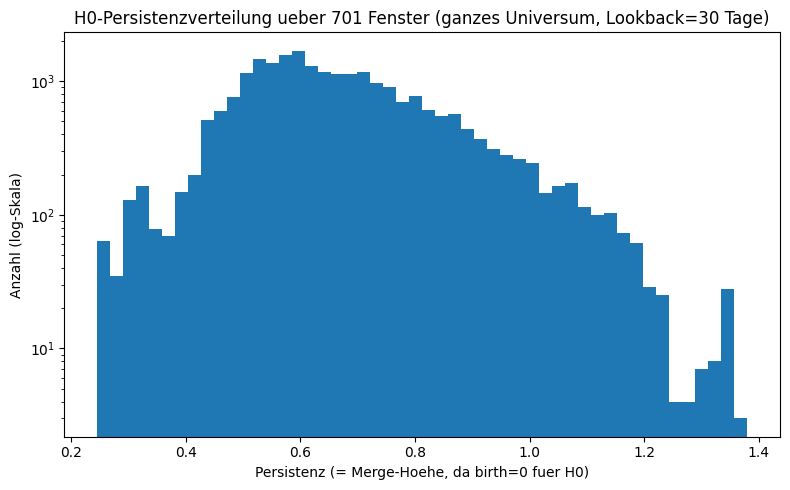

Perzentile:
  50%: 0.6447
  75%: 0.7728
  90%: 0.9113
  95%: 1.0032
  99%: 1.1542


In [169]:
# --- Persistenz-Schwelle bestimmen: Rohverteilung (ganzes Universum) ---
# H0-Persistenzwerte = Merge-Hoehen aus dem Single-Linkage-Dendrogramm (birth ist
# fuer H0 immer 0 -> persistence = death - 0 = Merge-Hoehe). Deckt JEDES moegliche
# Datum ab (keine Stichprobe), bei FESTEM Lookback (WINDOW_DAYS, wie oben
# gewaehlt). Das erste gueltige Datum haengt vom Lookback ab: ein laengeres
# Fenster braucht mehr Vorlauf, der Startpunkt verschiebt sich also nach hinten,
# je groesser WINDOW_DAYS ist -- deshalb hier neu berechnet statt fest von data_min.
from scipy.cluster.hierarchy import linkage as _linkage_ph
from scipy.spatial.distance import squareform as _squareform_ph

if DATE is None or WINDOW_DAYS is None:
    print("Bitte zuerst oben ein gueltiges Lookback/Datum waehlen.")
else:
    first_valid_date = data_min + pd.Timedelta(days=WINDOW_DAYS - 1)
    all_dates = pd.date_range(first_valid_date, data_max, freq="D", tz="UTC")

    all_persistence_values = []
    n_windows_used = 0

    for i, sample_ts in enumerate(all_dates):
        sample_result = helper.build_point_cloud(
            ohlcv_df         = ohlcv_df,
            universe_df      = universe_df,
            end_date         = sample_ts,
            window_size_days = WINDOW_DAYS,
            exclude_asset_ids= excluded_ids,
        )

        if sample_result is not None and sample_result["n_dimensions"] >= 2:
            sample_syms = [id_to_symbol.get(a, f"ID:{a}") for a in sample_result["asset_ids"]]
            sample_returns_df = pd.DataFrame(
                sample_result["point_cloud"], columns=sample_syms, index=sample_result["timestamps"]
            )
            sample_dist_matrix = helper.correlation_distance(sample_returns_df)
            z = _linkage_ph(_squareform_ph(sample_dist_matrix, checks=False), method="single")
            all_persistence_values.extend(z[:, 2].tolist())
            n_windows_used += 1

        if (i + 1) % 50 == 0:
            print(f"  ... {i + 1}/{len(all_dates)} Daten verarbeitet")

    print(f"Fenster verwendet: {n_windows_used} von {len(all_dates)} moeglichen Daten (Lookback={WINDOW_DAYS} Tage)")
    print(f"Gesamtzahl H0-Persistenzwerte (Merge-Hoehen): {len(all_persistence_values)}")

    if all_persistence_values:
        fig, ax = plt.subplots(figsize=(8, 5))
        ax.hist(all_persistence_values, bins=50)
        ax.set_yscale("log")
        ax.set_xlabel("Persistenz (= Merge-Hoehe, da birth=0 fuer H0)")
        ax.set_ylabel("Anzahl (log-Skala)")
        ax.set_title(f"H0-Persistenzverteilung ueber {n_windows_used} Fenster (ganzes Universum, Lookback={WINDOW_DAYS} Tage)")
        plt.tight_layout()
        plt.show()

        percentiles = [50, 75, 90, 95, 99]
        pct_values = np.percentile(all_persistence_values, percentiles)
        print("Perzentile:")
        for p, v in zip(percentiles, pct_values):
            print(f"  {p}%: {v:.4f}")

# 2. Multiple Baskets

In [170]:
# --- Basket-Vergleich vorbereiten ---
# Nutzt dieselbe Lookback/Datum-Auswahl wie oben (DATE, WINDOW_DAYS aus der
# Point-Cloud-Zelle). Nach einer Aenderung dort diese Zelle erneut ausfuehren.
# Anzahl Baskets und Grenzen kommen aus POINTCLOUD_BASKET_UPPER_BOUNDS weiter oben
# (Liste editieren + diese Zelle neu ausfuehren, um z.B. 3 oder 4 Baskets zu testen).
basket_comparison_results: dict = {}

if DATE is None or WINDOW_DAYS is None:
    print("Bitte zuerst oben ein gueltiges Lookback/Datum waehlen.")
else:
    all_asset_ids = set(universe_df[ASSET_ID_COL].unique())

    basket_df_at_end = helper.build_volume_baskets(
        rolling_volume_df,
        DATE,
        id_column=ASSET_ID_COL,
        date_column=DATE_COL,
        basket_upper_bounds=POINTCLOUD_BASKET_UPPER_BOUNDS,
    )

    for label in basket_labels:
        basket_asset_ids = set(basket_df_at_end.loc[basket_df_at_end["basket"] == label, ASSET_ID_COL])
        n_members = len(basket_asset_ids)

        # Weniger als 2 Assets -> keine paarweise Distanz berechenbar. Statt zu
        # crashen, wird der Grund vermerkt und in der Vergleichs-Ansicht unten
        # als Hinweistext statt eines Plots angezeigt.
        if n_members == 0:
            basket_comparison_results[label] = {"status": "empty", "n_members": 0}
            continue

        if n_members == 1:
            only_symbol = id_to_symbol.get(next(iter(basket_asset_ids)), "?")
            basket_comparison_results[label] = {
                "status": "single", "n_members": 1, "symbol": only_symbol,
            }
            continue

        basket_exclude_ids = excluded_ids | (all_asset_ids - basket_asset_ids)
        result_local = helper.build_point_cloud(
            ohlcv_df         = ohlcv_df,
            universe_df      = universe_df,
            end_date         = DATE,
            window_size_days = WINDOW_DAYS,
            exclude_asset_ids= basket_exclude_ids,
        )

        if result_local is None:
            basket_comparison_results[label] = {"status": "no_data", "n_members": n_members}
            continue

        basket_syms = [id_to_symbol.get(i, f"ID:{i}") for i in result_local["asset_ids"]]
        basket_returns_df = pd.DataFrame(
            result_local["point_cloud"], columns=basket_syms, index=result_local["timestamps"]
        )
        basket_dist_matrix = helper.correlation_distance(basket_returns_df)

        basket_comparison_results[label] = {
            "status": "ok",
            "n_members": len(basket_syms),
            "syms": basket_syms,
            "dist_matrix": basket_dist_matrix,
            "n_points": result_local["n_points"],
        }

    print(f"Basket-Vergleich vorbereitet fuer {DATE.date()} ({WINDOW_DAYS} Tage Lookback):")
    for label in basket_labels:
        info = basket_comparison_results[label]
        if info["status"] == "empty":
            print(f"  {label}: keine Assets an diesem Datum")
        elif info["status"] == "single":
            print(f"  {label}: nur 1 Asset ({info['symbol']}) — keine paarweise Distanz moeglich")
        elif info["status"] == "no_data":
            print(f"  {label}: {info['n_members']} Assets, aber zu wenig gemeinsame Preis-Historie")
        else:
            print(f"  {label}: {info['n_members']} Assets, {info['n_points']} Punkte")

Basket-Vergleich vorbereitet fuer 2026-07-22 (30 Tage Lookback):
  Basket 1: 10 Assets, 8351 Punkte
  Basket 2: 19 Assets, 8639 Punkte


--- Basket 1 ---


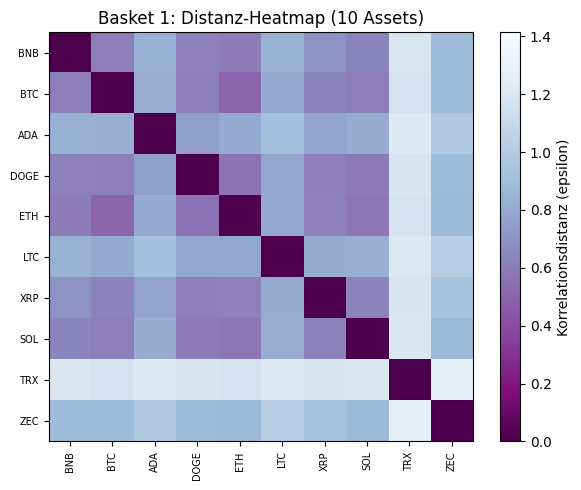

--- Basket 2 ---


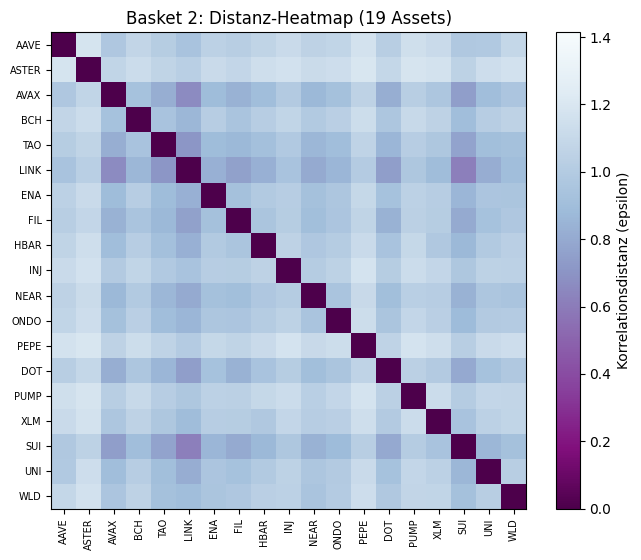

In [171]:
# --- Basket-Vergleich: Heatmaps ---
for label in basket_labels:
    info = basket_comparison_results.get(label)
    print(f"--- {label} ---")

    if info is None:
        print("(noch nicht vorbereitet — vorherige Zelle ausfuehren)")
        continue
    if info["status"] == "empty":
        print("keine Assets an diesem Datum.")
        continue
    if info["status"] == "single":
        print(f"nur 1 Asset ({info['symbol']}) — keine paarweise Distanz moeglich.")
        continue
    if info["status"] == "no_data":
        print(f"{info['n_members']} Assets, aber zu wenig gemeinsame Preis-Historie fuer eine Point Cloud.")
        continue

    dist_matrix = info["dist_matrix"]
    syms = info["syms"]
    n = info["n_members"]

    dist_df = pd.DataFrame(dist_matrix, columns=syms, index=syms)
    fig, ax = plt.subplots(figsize=(max(6, n * 0.35), max(5, n * 0.3)))
    im = ax.imshow(dist_df.values, vmin=0, vmax=np.sqrt(2), cmap="BuPu_r", aspect="auto")
    plt.colorbar(im, ax=ax, label="Korrelationsdistanz (epsilon)")
    ax.set_xticks(range(n)); ax.set_xticklabels(syms, rotation=90, fontsize=7)
    ax.set_yticks(range(n)); ax.set_yticklabels(syms, fontsize=7)
    ax.set_title(f"{label}: Distanz-Heatmap ({n} Assets)")
    plt.tight_layout()
    plt.show()
    plt.close("all")

--- Basket 1 ---


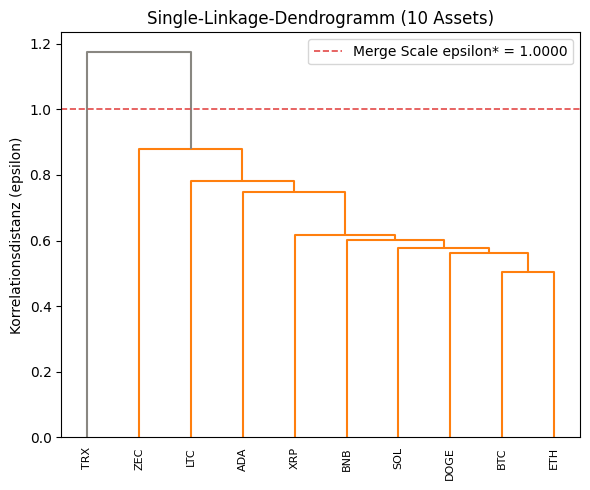

--- Basket 2 ---


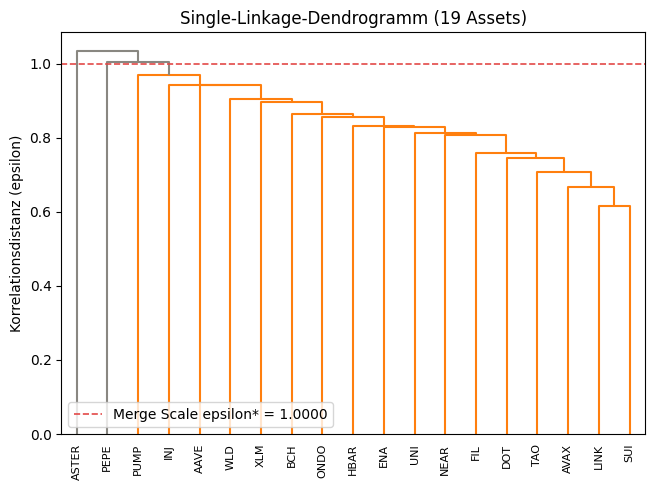

In [172]:
# --- Basket-Vergleich: Dendrogramme ---
from cloudvisualisation import plot_dendrogram

# Merge Scale fest auf 1.0, gleich fuer alle Baskets.
merge_scale = 1.0

for label in basket_labels:
    info = basket_comparison_results.get(label)
    print(f"--- {label} ---")

    if info is None:
        print("(noch nicht vorbereitet — vorherige Zelle ausfuehren)")
        continue
    if info["status"] == "empty":
        print("keine Assets an diesem Datum.")
        continue
    if info["status"] == "single":
        print(f"nur 1 Asset ({info['symbol']}) — keine paarweise Distanz/Cluster moeglich.")
        continue
    if info["status"] == "no_data":
        print(f"{info['n_members']} Assets, aber zu wenig gemeinsame Preis-Historie fuer eine Point Cloud.")
        continue

    dist_matrix = info["dist_matrix"]
    syms = info["syms"]
    n = info["n_members"]

    plot_dendrogram(dist_matrix, syms, color_threshold=merge_scale, figsize=(max(6, n * 0.35), 5))

In [173]:
# --- Basket-Vergleich: Vietoris-Rips-Skelette ---
from cloudvisualisation import plot_vietoris_rips_epsilon_slider

for label in basket_labels:
    info = basket_comparison_results.get(label)
    print(f"--- {label} ---")

    if info is None:
        print("(noch nicht vorbereitet — vorherige Zelle ausfuehren)")
        continue
    if info["status"] == "empty":
        print("keine Assets an diesem Datum.")
        continue
    if info["status"] == "single":
        print(f"nur 1 Asset ({info['symbol']}) — keine paarweise Distanz/Cluster moeglich.")
        continue
    if info["status"] == "no_data":
        print(f"{info['n_members']} Assets, aber zu wenig gemeinsame Preis-Historie fuer eine Point Cloud.")
        continue

    dist_matrix = info["dist_matrix"]
    syms = info["syms"]

    plot_vietoris_rips_epsilon_slider(dist_matrix, syms, max_edge_length=np.sqrt(2))

--- Basket 1 ---


--- Basket 2 ---


  ... 50/701 Daten verarbeitet
  ... 100/701 Daten verarbeitet
  ... 150/701 Daten verarbeitet
  ... 200/701 Daten verarbeitet
  ... 250/701 Daten verarbeitet
  ... 300/701 Daten verarbeitet
  ... 350/701 Daten verarbeitet
  ... 400/701 Daten verarbeitet
  ... 450/701 Daten verarbeitet
  ... 500/701 Daten verarbeitet
  ... 550/701 Daten verarbeitet
  ... 600/701 Daten verarbeitet
  ... 650/701 Daten verarbeitet
  ... 700/701 Daten verarbeitet
Basket 1: 701 von 701 moeglichen Fenstern verwendet, 12760 Persistenzwerte


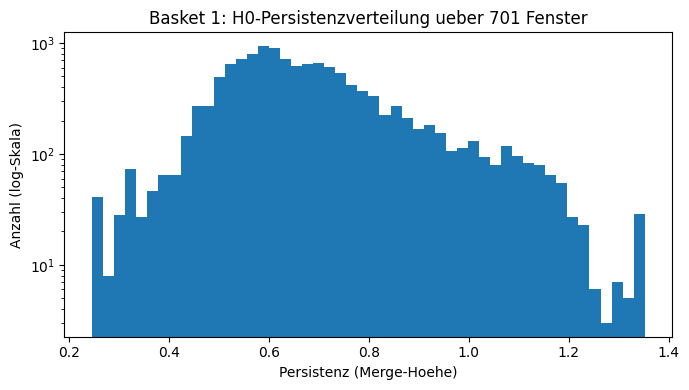

  Perzentile: 50%=0.6491, 75%=0.7685, 90%=0.9311, 95%=1.0524, 99%=1.1858
Basket 2: 701 von 701 moeglichen Fenstern verwendet, 10463 Persistenzwerte


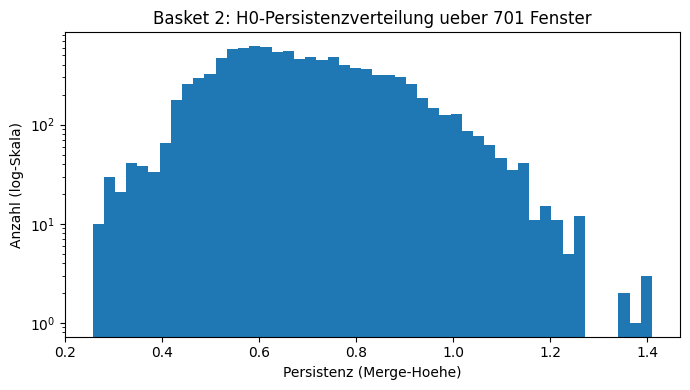

  Perzentile: 50%=0.6706, 75%=0.8063, 90%=0.9210, 95%=0.9976, 99%=1.1300


In [174]:
# --- Persistenz-Schwelle bestimmen: Rohverteilung PRO Basket ---
# Gleiches Prinzip wie die Ganz-Universum-Version am Ende von Kapitel 1, aber pro
# Basket separat gesammelt (eigene Mitgliederliste + eigener exclude_asset_ids-Filter
# an jedem Datum, wie in der Basket-Vergleich-Vorbereitung oben). Keine
# Stichprobe -> jedes moegliche Datum, bei FESTEM WINDOW_DAYS-Lookback.
from scipy.cluster.hierarchy import linkage as _linkage_ph2
from scipy.spatial.distance import squareform as _squareform_ph2

if DATE is None or WINDOW_DAYS is None:
    print("Bitte zuerst oben ein gueltiges Lookback/Datum waehlen.")
else:
    first_valid_date = data_min + pd.Timedelta(days=WINDOW_DAYS - 1)
    all_dates = pd.date_range(first_valid_date, data_max, freq="D", tz="UTC")
    all_asset_ids = set(universe_df[ASSET_ID_COL].unique())

    persistence_by_basket: dict[str, list[float]] = {label: [] for label in basket_labels}
    windows_used_by_basket: dict[str, int] = {label: 0 for label in basket_labels}

    for i, sample_ts in enumerate(all_dates):
        basket_df_at_sample = helper.build_volume_baskets(
            rolling_volume_df,
            sample_ts,
            id_column=ASSET_ID_COL,
            date_column=DATE_COL,
            basket_upper_bounds=POINTCLOUD_BASKET_UPPER_BOUNDS,
        )

        for label in basket_labels:
            basket_asset_ids = set(
                basket_df_at_sample.loc[basket_df_at_sample["basket"] == label, ASSET_ID_COL]
            )
            if len(basket_asset_ids) < 2:
                continue

            basket_exclude_ids = excluded_ids | (all_asset_ids - basket_asset_ids)
            res = helper.build_point_cloud(
                ohlcv_df         = ohlcv_df,
                universe_df      = universe_df,
                end_date         = sample_ts,
                window_size_days = WINDOW_DAYS,
                exclude_asset_ids= basket_exclude_ids,
            )
            if res is None or res["n_dimensions"] < 2:
                continue

            b_syms = [id_to_symbol.get(a, f"ID:{a}") for a in res["asset_ids"]]
            b_returns_df = pd.DataFrame(res["point_cloud"], columns=b_syms, index=res["timestamps"])
            b_dist_matrix = helper.correlation_distance(b_returns_df)
            z = _linkage_ph2(_squareform_ph2(b_dist_matrix, checks=False), method="single")
            persistence_by_basket[label].extend(z[:, 2].tolist())
            windows_used_by_basket[label] += 1

        if (i + 1) % 50 == 0:
            print(f"  ... {i + 1}/{len(all_dates)} Daten verarbeitet")

    for label in basket_labels:
        values = persistence_by_basket[label]
        print(
            f"{label}: {windows_used_by_basket[label]} von {len(all_dates)} "
            f"moeglichen Fenstern verwendet, {len(values)} Persistenzwerte"
        )

        if not values:
            continue

        fig, ax = plt.subplots(figsize=(7, 4))
        ax.hist(values, bins=50)
        ax.set_yscale("log")
        ax.set_xlabel("Persistenz (Merge-Hoehe)")
        ax.set_ylabel("Anzahl (log-Skala)")
        ax.set_title(f"{label}: H0-Persistenzverteilung ueber {windows_used_by_basket[label]} Fenster")
        plt.tight_layout()
        plt.show()

        percentiles = [50, 75, 90, 95, 99]
        pct_values = np.percentile(values, percentiles)
        print("  Perzentile: " + ", ".join(f"{p}%={v:.4f}" for p, v in zip(percentiles, pct_values)))